#Preamble

This mini-project involves working through all the steps of a problem, whereas prior assignments asked you to just implement core functions. We will give you a dataset, but you will also have the opportunity to manipulate the data in ways that you find beneficial to the overall project and to explain why and how those manipulations mattered. This will be in addition to building the model from scratch, developing the training loop, and implementing testing. The code will be accompanied by a report written into the notebook.

This project will have you working with attention mechanism, in a new type of system for question-answering. This will provide you with experience working with attention mechanisms while not directly working with transformers.

This assignment is not autograded. You can modify any code cells as long as you achieve the requirements of each graded component.

# Introduction

Memory networks learn to access external memory stores (a database or, in the case of this assignment, a dictionary). Key-Value Memory Networks specifically assume that the external memory store is organized as a dictionary with keys and values. In theory memory networks are useful when one wants a neural network to be able to know a lot of information but we don't want to try to encode that information directly into the parameters of the network. This means information can be changed in the external memory database without retraining the neural network.

Given a question, e.g., "Where was Alexander Hamilton born?", a key-value memory network learns an embedding such that the question has a high cosine similarity to a particular key in the external dictionary. Because there are many keys that need to be matched against, key-value memory networks implement an attention-scoring mechanism to select a key. Because attention is a probabilistic score, the key-value memory network retrieves a sum of embeddings weighted according to the attention score. This weighted embedding is then compared to values using a second attention-scoring mechanism. The value with the highest cosine similarity can then be retrieved and returned as the answer.

Memory networks were an important part of the evolution of question-answering systems that have been eclipsed by transformers. However, the attention mechanism in a key-value memory network is very similar to the self-attention inside a transformer, so implementing a key-value memory network is a really great way to experiment and learn about self-attention without the added complexity of transformers.

Key-value memory networks are also closely related to retieval-based generation networks, except we will be retrieving facts from a dictionary instead of via the internet. However, the embedding of retrieved data will be similar.

Key-value memory networks are described in this [paper](https://arxiv.org/abs/1606.03126). It is recommended that you read the paper, but we will also walk through the steps you will need to complete.

# Some imports



You may add imports as necessary.

In [1]:
import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F
import re
import os
import json
import random
import numpy as np
import pickle
from tqdm import tqdm
import nltk
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

Unidecode is useful for getting rid of issues that arise from unicode. This should not be used if we care about unicode, but for the purposes of an instructional exercise, it eliminates a lot of edge cases that come up with unicode.

In [3]:
!pip install unidecode

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 235.8/235.8 kB 12.4 MB/s eta 0:00:00


In [4]:
import unidecode

If you need to have a reduced vocabulary, you can create an unknown "unk" token and add it to the vocabulary. Make sure the token index in the vocabulary and `UNK_ID` match.

In [5]:
UNK = 'unk'
UNK_ID = '0'

# Some utilities

You may edit these as necessary.

Stem words

In [6]:
# Stemming the text
def simple_stemmer(text):
    ps=nltk.porter.PorterStemmer()
    text= [ps.stem(word) for word in text]
    return text

Simple tokenizer that only keeps letters and numbers.

In [7]:
def tokenize(line):
    line = re.sub(r'[^a-zA-Z0-9]', ' ', unidecode.unidecode(line)) # remove punctuation
    line = line.lower().split()  # lower case
    return line

A standard vocabulary object class

In [8]:
class Vocab:
    def __init__(self, name = 'vocab'):
        self.name = name
        self._word2index = {}
        self._word2count = {}
        self._index2word = {}
        self._n_words = 0

    def get_words(self):
      return list(self._word2count.keys())

    def num_words(self):
      return self._n_words

    def word2index(self, word):
      return self._word2index[word]

    def index2word(self, word):
      return self._index2word[word]

    def word2count(self, word):
      return self._word2count[word]

    def add_sentence(self, sentence):
        for word in tokenize(sentence):
            self.add_word(word)

    def add_word(self, word):
        if word not in self._word2index:
            self._word2index[word] = self._n_words
            self._word2count[word] = 1
            self._index2word[self._n_words] = word
            self._n_words += 1
        else:
            self._word2count[word] += 1

Make a bag of words frmo a sentence, given a vocabulary. Can return a bag of word counts or a a bag of word presences.

In [9]:
def multihot(s, vocab, preserve_counts = False):
  tokens = np.array([vocab.word2index(t) for t in tokenize(s)])
  mhot = np.zeros((tokens.size, vocab.num_words()))
  mhot[np.arange(tokens.size), tokens] = 1
  if preserve_counts:
    return mhot.sum(0)
  else:
    return mhot.sum(0) >= 1


If you have a reduced vocabulary, use this to replace out-of-vocab words. If you use this, you may want to merge it with `multihot` above to avoid tokenizing twice.

In [10]:
def unkit(s, vocab):
  return ' '.join(list(map(lambda x: UNK if x not in vocab._word2index else x, tokenize(s))))

# Part A: Download and Process Data (0 points)

This dataset contains the information in tables that are commonly used in Wikipedia biography pages. Each person has different rows of information pertaining to their notable accomplishments and details about their life. There are a large number of types of information that can appear as rows in the biography tables, however they are relatively uniform. We call the keys of the rows "relations".

For example [Alexander Hamilton](https://en.wikipedia.org/wiki/Alexander_Hamilton) has information about the President he worked for as Secretary of State, birth date, date of death, parents' names, etc.

The code below will download the dataset and process it to create two things:
- `DB`: a hash table that map titles of biography wikipedia articles to table information. The table information is represented as a nested hash table containing relations as keys, and associated values. For example, `DB['alexander hamilton'] = {'party': 'federalist',
 'spouse': 'elizabeth schuyler', ...}`
- `VOCAB`: A vocabulary object that maps words to tokens and vice versa.

In [11]:
!git clone https://github.com/rlebret/wikipedia-biography-dataset.git

Cloning into 'wikipedia-biography-dataset'...
remote: Enumerating objects: 93, done.
remote: Total 93 (delta 0), reused 0 (delta 0), pack-reused 93 (from 1)
Receiving objects: 100% (93/93), 338.68 MiB | 17.14 MiB/s, done.
Resolving deltas: 100% (43/43), done.


In [12]:
!cat wikipedia-biography-dataset/wikipedia-biography-dataset.z?? > tmp.zip
!unzip -o tmp.zip
!rm tmp.zip

Archive:  tmp.zip
   creating: wikipedia-biography-dataset/test/
  inflating: wikipedia-biography-dataset/test/test.box  
  inflating: wikipedia-biography-dataset/test/test.id  
  inflating: wikipedia-biography-dataset/test/test.nb  
  inflating: wikipedia-biography-dataset/test/test.sent  
  inflating: wikipedia-biography-dataset/test/test.url  
  inflating: wikipedia-biography-dataset/test/test.contributors  
  inflating: wikipedia-biography-dataset/test/test.title  
   creating: wikipedia-biography-dataset/train/
  inflating: wikipedia-biography-dataset/train/train.box  
  inflating: wikipedia-biography-dataset/train/train.id  
  inflating: wikipedia-biography-dataset/train/train.nb  
  inflating: wikipedia-biography-dataset/train/train.sent  
  inflating: wikipedia-biography-dataset/train/train.url  
  inflating: wikipedia-biography-dataset/train/train.contributors  
  inflating: wikipedia-biography-dataset/train/train.title  
   creating: wikipedia-biography-dataset/valid/
  infla

Get all the wikipedia titles.

In [13]:
train_titles = []
with open("wikipedia-biography-dataset/train/train.title", "r") as file:
  for line in file:
    train_titles.append(line.rstrip())

Boxes contain all the information, with each line corresponding to a title in `titles`.

In [14]:
train_boxes = []
with open("wikipedia-biography-dataset/train/train.box", "r") as file:
  for line in file:
    train_boxes.append(line.rstrip())

This will make the DB object, a dictionary of dictionaries for each wikipedia title, which is more or less the same as names. This function only keeps politicians (containing the "office" key term) and strips out information about images. It can be improved in many ways.

In [15]:
# Make a dictionary of dictionaries
def make_db(titles, boxes):
  db = {} # The DB
  # Iterate through titles
  for i in tqdm(range(len(titles))):
    box = boxes[i] # Grab the corresponding box information
    d  = {} # Inner dictionary
    # Build a dict for the ith entry
    # grab each key:value pair
    for pair in re.findall(r'([a-zA-Z_]+)[0-9]*\:([\w\d]+)', box):
      key, value = pair
      # Do a bit of cleaning
      key = key.strip()
      value = value.strip()
      # If the key contains the word image, we probably don't want to keep it
      if 'image' not in key:
        # The regex maintains underscores, strip those off
        if key[-1] == '_':
          key = key[:-1]
        # Make a new entry in inner dictionary if we don't have one
        if key not in d:
          d[key] = value
        # Keys with compound values are split up, which is annoying, so put them back together
        else:
          d[key] += ' ' + value
    # If it has an office key, keep it.
    if 'office' in d:
      db[titles[i]] = d
  return db

Build the vocab from the DB. Convert the whole thing into a string, tokenize it, and feed the surviving words into the vocab.

In [16]:
def make_vocab(DB):
  # Make the vocab object
  vocab = Vocab()
  # Tokenize the data by converting the entire DB into a string
  tokens = tokenize(str(DB))
  # Iterate through all the tokens (tqdm provides a progress bar)
  for t in tqdm(tokens):
    vocab.add_word(t)
  return vocab

If you want to discard rare words, this will rebuild the vocab. This is just an example.

In [17]:
def reduce_vocab(vocab, min_word_occurrence = 2):
  # make a new vocab
  vocab2 = Vocab("top")
  # Add the UNK token
  vocab2.add_word(UNK)
  # Iterate through vocabulary
  for w in list(vocab._word2count.keys()):
    count = vocab._word2count[w]
    idx = vocab._word2index[w]
    # If the word count passes threshold, add it to the new vocabulary object
    if count >= min_word_occurrence:
      vocab2.add_word(w)
      vocab2._word2count[w] = count
  # Return the new vocabulary object
  return vocab2

Make the DB

In [18]:
DB = make_db(train_titles, train_boxes)

100%|██████████| 582659/582659 [00:47<00:00, 12375.28it/s]


Make the VOCAB

In [19]:
VOCAB = make_vocab(DB)
print(VOCAB.num_words())

100%|██████████| 2997937/2997937 [00:01<00:00, 2605662.29it/s]

96093


## Save Processed Data

You may find it useful to save the processed dataset to your Google Drive.

It is recommended that you save the file to your Google Drive. To mount your Google Drive, open the file icon on the left side of the screen to get to the option). To save the file in your Google Drive use the path `'drive/MyDrive/filename'`.)

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [21]:
with open("drive/MyDrive/data", "wb") as f:
  pickle.dump(DB, f, protocol=None, fix_imports=True, buffer_callback=None)

In [22]:
with open('drive/MyDrive/vocab', 'wb') as f:
    pickle.dump(VOCAB, f, protocol=None, fix_imports=True, buffer_callback=None)

## Load processed data

If you have saved the processed data in your Google Drive, you can re-load it with these commands.

In [23]:
with open("drive/MyDrive/vocab", "rb") as f:
  VOCAB = pickle.load(f)

In [24]:
with open("drive/MyDrive/data", "rb") as f:
  DB = pickle.load(f)

## Data example

Get to know your data.

In [25]:
DB["alexander hamilton"]

{'name': 'alexander hamilton',
 'office': '1st united states secretary of the treasury senior officer of the army delegate to the congress of the confederation from new york',
 'president': 'george washington john adams',
 'term_start': 'september 11 1789 december 14 1799 november 3 1788 november 4 1782',
 'term_end': 'january 31 1795 june 15 1800 march 2 1789 june 21 1783',
 'predecessor': 'position established george washington egbert benson seat established',
 'successor': 'oliver wolcott jr james wilkinson seat abolished seat abolished',
 'birth_date': '11 january 1755',
 'birth_place': 'charlestown nevis british west indies',
 'death_date': 'july 12 1804 aged 47 or 49',
 'death_place': 'new york city new york u',
 'party': 'federalist',
 'spouse': 'elizabeth schuyler',
 'children': 'philip angelica alexander james alexander john church william stephen eliza holly phil',
 'alma_mater': 'kings college new york',
 'religion': 'presbyterian episcopalian convert',
 'signature': 'alexan

# Part B: Implement the Key-Value Memory Network (10 points)

This [paper](https://arxiv.org/abs/1606.03126) describes the key-value memory networks in detail, which is also sketched out below.

A key-value memory network takes a natural language question. This question will be converted into a bag-of-words (i.e., a multihot) Call this $x$ and it is a 1D tensor of vocabulary length.

![KVMemNet architecture](https://github.com/markriedl/kvmemnet-assignment/blob/32479dd1e88a9f8dfc72f11ccb8e9e0e1f78905f/kvmemnet-inside.png?raw=true)

The KVMemNet will contain a linear layer (or embedding layer) that will produce a 1D embedding of the question $q=A(x)$.

The KVMemNet will also take in a stack of keys as a tensor of shape `num_keys x vocab_size`. Each row is embedded using the same embedding, $k=A(keys)$, producing a tensor of shape `num_keys x embed_dim`. How this stack of keys is chosen will be discussed below.

The KVMemNet will take in a third input, a stack of values associated with the stack of keys. This will also be of shape `num_values x vocab_size`. Each row is embedded using the same embedding, $v=A(values)$, producing a tensor of shape `num_keys x embed_dim`.

The KVMemNet will also contain a second linear embedding layer, $B$. More on this later.

Once we have `q`, `k`, and `v` embeddings, the next step is to use `q` and `k` to compute attention scores that can be applied against `v`. Think of $A$ as learning how to make questions and the keys that should match against values that have received the same treatment.

The attention scores `p` are computed by taking the inner-product (`torch.inner()`) between `q` and `k`. The result will be a 1D tensor with `num_keys` length. Use softmax so that `p` contains scores between 1.0 and 0.0.

You may be wondering why there isn't a non-linearity such as a sigmoid or ReLU after the linear layer. Softmax is a non-linearity.

Next apply the `p` attention scores against `v` to apply a weight against each value in the stack of values. One should be highly weighted and the rest less weighted. Sum all the weighted values up to create a 1D tensor `o` of feature weights of length `embed_dim`. `p` can be thought of as how much of each value gets selected. Then they all get combined together and the feature weights are proportional to how much each value was attended to. The `torch.matmul()` can do the multiplication and summing in one step.

The KVMemNet forward function should return this tensor of feature weights `o`.

A quick note on `k` and `v`. We can't send the entire set of keys and values in our database through the network's forward function. Instead there should be a selection mechanism that selects just a subset of the database. This subset should contain the best key for the question $x$ to match against, and its corresponding value. We assume that a shallow selection process can narrow down the key-value pairs to a relatively small set, one of which will be best. For example, if the question involves "Alexander Hamilton", we can reasonably guess that the best key-value pair is in the part of the database associated with the named person.

We are not done though. What about our linear layer $B$? Suppose variable `Y` contains our entire set of values in our databse as bags of words. $B$ is going to be used to embed our entire set of database values $y=B(Y)$. $B$ can be thought of as learning how to make all the values look like the feature weights output by the model such that the highest cosine similarity corresponds to the correct value taken from *all* values in the database.

$B$ should live inside the KVMemNet object so that its parameters become trainable, but notice that we do not use $B$ in the KVMemNet's forward function. $B$ will get used to prepare the stack of all values in the database for training. It will bet used in the training loop but outside of the forward function. This is a bit unusual, but necessary to figure out the correct target (the true index of the best value to match against) for training.

The above explantion only implements *single-hop* retrieval. *multi-hop* retrieval allows the results of one retrieval to inform a second (and third and so on) to get the right retrieval. This would be used in the case where the answer cannot be inferred directly from the question in a single retrieval, such as "What was the founding date of the country that Alexander Hamilton was born in?". To implement multi-hop retrieval, the KVMemNet will have additional linear layers $R_1...R_n$. Each $R_{i}$ will do a linear transform on `q` then attention will score and retrieve values as feature weights `o`. This will be sent to the next $R_{i+1}$ and so on until the hops are complete. This final `o` will be returned.

For this assignment is is sufficient to only do *single-hop* retrieval.

The above explanation does not include consideration of batching. You may want to add a batch dimension as the first dimension and input a batch as a set of questions, a set of stacks of keys, and a set of stacks of values. To do this, functions like `.inner()`, `.mm()`, and`.matmul()` will not work. Instead use `.bmm()` which handles batching correctly. You will probably need to do some `.squeeze()` and `.unsqueeze()` operations to make sure your tensors are the correct shapes.

Instead of bag-of-words, one may also consider first converting each question, key, and value into a general set of embeddings such as [GLoVe](https://nlp.stanford.edu/projects/glove/). To do this one will need to consider how to combine words--convert each word into an embedding vector and then add the vectors together (or maybe average them).

**Complete the key-value memory net code**

In [26]:
class KVMemNet(nn.Module):
  def __init__(self, vocab_size, embed_dim):
    super(KVMemNet, self).__init__()
    self.vocab_size = vocab_size
    self.embed_dim = embed_dim
    ### YOUR CODE HERE
    self.A=nn.Linear(vocab_size,embed_dim,bias=False)
    self.B=nn.Linear(vocab_size,embed_dim,bias=False)

  def forward(self, x, keys, values):
    output = None
    ### YOUR CODE BELOW
    q=self.A(x)
    k=self.A(keys)
    v=self.A(values)
    q=q.unsqueeze(2)
    scores_a=torch.bmm(k,q).squeeze(2)
    p=F.softmax(scores_a,dim=1)
    p=p.unsqueeze(1)
    output=torch.bmm(p,v).squeeze(1)

    ### YOUR CODE ABOVE
    return output


# Synthetic Data Set

This is a synthetic dataset. One way to test a model during development is to take a small piece of data and show that you can overfit a model. If you can't overfit an easily learned chunk of data, then you probably have something wrong in your code. In this case I have provided a small chunk of synthetic data that should be easy to learn.

- The vocabulary is 20 word: 5 names, 5 relations, 5 question-words, 5 values
 - First 5 elements of the vocab are names (for example index 0 might be "Hamilton").
 - Second 5 elements of the vocab are relations (for example, "born", "died", "occupation").
 - Third 5 elements are random words that might be part of a query (for example, "When was").
 - Final 5 elements of the vocab are possible values (for example, "1757")
- A "question" is a name (5, 1), relation (5, 1), some words (5, 1), and no values
- The keys will all have the same name (5, 5) where each row is idential, relations (5, 5), no words, no values
- Values will have no names, no relations, no words, and value vocab words

In [44]:
# Turn on a different relation on each row
relations = torch.zeros(5, 5)
relations.fill_diagonal_(1)

# training data
train_data = {}
for i in range(5):
  # Name associated with questions, keys, values
  train_data[i] = (torch.cat([F.one_hot(torch.arange(0, 5))[i].repeat(5, 1),
                         relations,
                         torch.randint(0, 2, (5, 5)).float(),
                         torch.zeros(5, 5)], dim=1),
              torch.cat([F.one_hot(torch.arange(0, 5))[i].repeat(5, 1),
                         relations,
                         torch.zeros(5, 5),
                         torch.zeros(5, 5)], dim=1),
              torch.cat([torch.zeros(5, 5),
                         torch.zeros(5, 5),
                         torch.zeros(5, 5),
                         torch.randint(0, 2, (5, 5)).float()], dim=1))
  Y = torch.cat([v[2] for v in list(train_data.values())], dim=0).to('cuda')

# Part C: Train on Synthetic Data (5 points)

The following describes the steps to set up a training loop, including the training of the $B$ layer.

![The KVMemNet being used in the training loop](https://github.com/markriedl/kvmemnet-assignment/blob/main/kvmemnet-outside.png?raw=true)

- Create a model with the given vocabulary size and an embedding size that is equal to or smaller.
- Loop through `N` epochs:
 - There are five names, loop through each name.
   - Get a stack of questions, stack of keys, and stack of values from `DB_synth`.
   - Loop through the relations. There is relation on each row of the keys and values.
     - Get a single question, the `i`-th row in the questions pulled from `DB_synth` above.
     - Compute the target: this is the `name*5 + i` element in `Y`.
     - Run the singular question, stack of keys, and stack of values through the model and produce an output, which is a tensor of feature weights.
     - Run all of `Y` through `model.B()` to get an embedded stack of values.
     - Take the softmax of the inner product between the embedded stack of values from `Y` and the feature weight generated by the model.
     - Compute the loss with `nn.CrossEntropyLoss`.
     - Call `.backward()` on the loss.

In addition to printing the loss (after every question or after every name in `DB_synth`) you can also print the target and the argmax of the softmax result to see if they match. Over time you should see the target and the argmax in agreement. For the purposes of this part of the project it is sufficient to test on the training set.

Don't forget to move the model and the tensor to the GPU.

You may want to speed up training by implementing batching. To do this, the model `forward()` needs to take tensors with an extra batching dimension as the first dimension. However, `.inner()`, `.mm()`, and `.matmul()` will not work properly. You will need to use `.bmm()` instead, which understands the first dimension is for batching. You will likely find that you need to perform some `.squeeze()` and `.unsqueeze()` operations. You can try batch-size of one, or take entire chunks (or even all synthetic data as a single, large batch). Try it different ways.

Try training on the synthetic data first.

You may make as many cells as necessary. Save your notebook outputs that plot loss and show it reducing.

**Write code blocks below that create the `KVMemNet`**

In [68]:
# Hyperparameters
vocab_size = 20
embed_dim = 16
lr = 0.001
num_epochs = 1000
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [69]:
# Set up your KVMemNet, move it to the GPU, setup up optimizer (e.g., Adam), and criterion.
model=KVMemNet(vocab_size, embed_dim).to(device)
optimizer=optim.Adam(model.parameters(),lr=lr)
CE_loss=nn.CrossEntropyLoss()

**Write and run a training testing loop. Show that your training loop loss converges with a plot**

To plot a loss curve, compute the mean loss per epoch and save it in a list:
```
x_axis.append(epoch_number)
y_axis.append(mean_epoch_loss_for_this_epoch)
plt.plot(x_axis, y_axis)
plt.show()
```

In [70]:
# Write your training loop here
x_axis,y_axis=[],[]
Y=Y.to(device)

for epoch_number in range(num_epochs):
  Y_embed = model.B(Y)
  loss_e=0.0
  corr,total=0,0
  for id, (q,k,v) in train_data.items():
    q=q.to(device)
    k=k.to(device)
    v=v.to(device)

    for i in range(5):
      q_1=q[i].unsqueeze(0)
      target=torch.tensor([id*5+i],device=device)

      o=model(q_1,k.unsqueeze(0),v.unsqueeze(0))
      Y_embed=model.B(Y)
      raw_score=torch.matmul(o,Y_embed.T)
      #loss
      loss=CE_loss(raw_score,target)
      loss_e+=loss.item()
      #backprop
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      pred=torch.argmax(raw_score, dim=1)
      corr+=(pred==target).sum().item()
      total+= 1

  mean_epoch_loss_for_this_epoch=loss_e/total
  x_axis.append(epoch_number)
  y_axis.append(mean_epoch_loss_for_this_epoch)

  if epoch_number%20==0 or epoch_number==num_epochs-1:
        acc = 100.0 * corr/total
        print(f"Epoch: {epoch_number:03d}| Mean Loss: {mean_epoch_loss_for_this_epoch:.4f}| Accuracy: {acc:.1f}%")


Epoch: 000| Mean Loss: 3.2243| Accuracy: 8.0%
Epoch: 020| Mean Loss: 2.7725| Accuracy: 32.0%
Epoch: 040| Mean Loss: 1.4593| Accuracy: 76.0%
Epoch: 060| Mean Loss: 0.8058| Accuracy: 84.0%
Epoch: 080| Mean Loss: 0.5547| Accuracy: 84.0%
Epoch: 100| Mean Loss: 0.4360| Accuracy: 84.0%
Epoch: 120| Mean Loss: 0.3679| Accuracy: 84.0%
Epoch: 140| Mean Loss: 0.3247| Accuracy: 84.0%
Epoch: 160| Mean Loss: 0.2959| Accuracy: 84.0%
Epoch: 180| Mean Loss: 0.2761| Accuracy: 84.0%
Epoch: 200| Mean Loss: 0.2620| Accuracy: 84.0%
Epoch: 220| Mean Loss: 0.2519| Accuracy: 84.0%
Epoch: 240| Mean Loss: 0.2445| Accuracy: 84.0%
Epoch: 260| Mean Loss: 0.2390| Accuracy: 84.0%
Epoch: 280| Mean Loss: 0.2349| Accuracy: 84.0%
Epoch: 300| Mean Loss: 0.2318| Accuracy: 84.0%
Epoch: 320| Mean Loss: 0.2295| Accuracy: 84.0%
Epoch: 340| Mean Loss: 0.2277| Accuracy: 84.0%
Epoch: 360| Mean Loss: 0.2264| Accuracy: 84.0%
Epoch: 380| Mean Loss: 0.2253| Accuracy: 84.0%
Epoch: 400| Mean Loss: 0.2245| Accuracy: 84.0%
Epoch: 420| Me

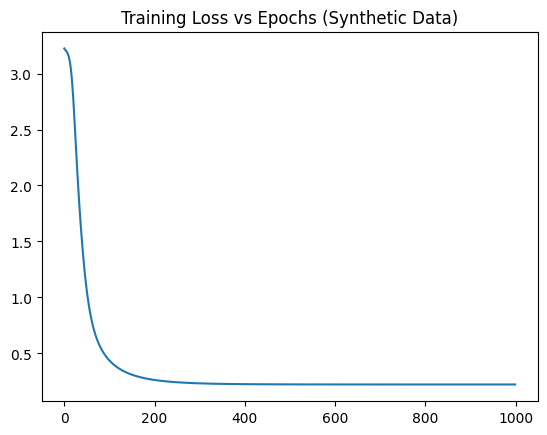

In [100]:
plt.title("Training Loss vs Epochs (Synthetic Data)")
x_axis.append(epoch_number)
y_axis.append(mean_epoch_loss_for_this_epoch)
plt.plot(x_axis, y_axis)
plt.show()

# Part D: Training on the Full Data (10 points)

To train on the full data, you are going to need to do some pre-processing of the data.

First, there are no "questions". You need to generate questions for each type of relation. There a number of ways to do this. The simplest is to just assume that a question is the name of a person and a relation, e.g., "Alexander Hamilton birth date". Another way would be to create templates for each type of relation. For example the "birth date" relation would have the following template: "When was [name] born?", filling in the [name]. Because there are a lot of different types of relations, you may want to remove the more obscure relations so you need fewer templates and also have a smaller vocabulary. Templates work well if the questions are expected to be almost identical to the templates. You may want to generate multiple templates per relation. Continuing the previous example, a second template would be: "What is the birthdate of [name]?".

If you are feeling more ambitious, you could use GPT-J, GPT-NeoX, GPT-3 or ChatGPT to generate templates. It works decently well and you can get some variety of templates.

The question should contain information about the person and some words that are representative of the relation even if the exact relation words aren't used (the KVMemNet should figure out that "birthdate" and "born" are correlated).

You only put a subset of all key-value pairs into the KVMemNet. You need a technique for sub-selecting from all the key-value pairs in `DB`. You might just need the ones that are directly associated with the person (Alexander Hamilton has 23). You may need to mix in a few key-value pairs from another person's entries in the database to help ensure against accidental overfitting.

The final challenge you will have in the training loop is that there may still be too many unique values in `Y` to encode and create one big tensor. In that case, you can at least use the values that you sent to the KVMemNet, along with as many other randomly selected values as you can fit into the GPU's memory.

Create as many cells below as you need. Save the output of your training and testing functions, reporting loss during training and accuracy during testing. 5 points for a training loop that reduces loss. 5 points for a training function with a correct accuracy computation.

**Create a training dataset and a non-overlapping testing dataset**

If CPU memory becomes a problem you might want to consider a `DataLoader` so that data can be stored on file and pulled up when needed.

In [72]:
# Create your training and test sets here
def multihot_2(s, vocab, preserve_counts = False):
  s_clean=unkit(s,vocab)
  tokens=tokenize(s_clean)
  idxs=np.array([vocab.word2index(t) for t in tokens],dtype=int)
  mhot = np.zeros((idxs.size,vocab.num_words()),dtype=float)
  mhot[np.arange(idxs.size),idxs] = 1
  collapsed = mhot.sum(0)
  if preserve_counts:
    return torch.tensor(collapsed, dtype=torch.float32)
  else:
    return torch.tensor((collapsed >= 1).astype(float), dtype=torch.float32)

In [74]:
#create memory data for each person
if "unk" not in VOCAB._word2index:
    VOCAB.add_word("unk")

MAX_RELS = 20 #max relations to use
N = 600            #total people to load
memory_data={}
cnt=0

for name,info in DB.items():

    if cnt >= N:
        break

    keys= []
    vals= []
    rels= []

    for rel,val in info.items():

        if rel in ["name", "article_title", "signature"]: #remove obscure relations
            continue

        if val is None or str(val).strip() == "":
            continue

        k_vec = multihot_2(rel, VOCAB)
        v_vec = multihot_2(str(val), VOCAB)

        if torch.sum(v_vec) == 0:
            continue

        keys.append(k_vec)
        vals.append(v_vec)
        rels.append(rel)

        if len(keys) >= MAX_RELS:
            break

    if len(keys) > 0:
        memory_data[name] = {
            "keys": torch.stack(keys),
            "vals": torch.stack(vals),
            "rels": rels
        }
        cnt += 1

print("Num people:", len(memory_data))


Num people: 600


In [75]:
ppl = list(memory_data.keys())

train_ppl = ppl[:500]
test_ppl  = ppl[500:600]

print("#train people:", len(train_ppl))
print("#test people:", len(test_ppl))

#train people: 500
#test people: 100


In [76]:
#creating training data
train_data= []
for name in train_ppl:
    pdata=memory_data[name]
    rels=pdata["rels"]
    for rel_idx,rel in enumerate(rels):
        q_text = f"{name} {rel}"
        q_vec =multihot_2(q_text, VOCAB)
        train_data.append({
            "name":name,
            "rel_idx":rel_idx,
            "Q":q_vec
        })

#creating test data
test_data= []
for name in test_ppl:
    pdata=memory_data[name]
    rels=pdata["rels"]
    for rel_idx,rel in enumerate(rels):
        q_text = f"{name} {rel}"
        q_vec =multihot_2(q_text, VOCAB)
        test_data.append({
            "name":name,
            "rel_idx":rel_idx,
            "Q":q_vec
        })

print("train size:", len(train_data))
print("test size:", len(test_data))


train size: 5844
test size: 1157


**Create your `KVMemNet`**

In [81]:
# Set up your KVMemNet here
embed_dim = 64
learning_rate = 0.001
num_epochs = 15

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

model= KVMemNet(VOCAB.num_words(),embed_dim).to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate)
CE_loss=torch.nn.CrossEntropyLoss()

cuda


**Write and run a training loop, showing a loss plot**

You may find it handy to also test your network on the test data periodically as it trains.

In [82]:
train_names= train_ppl
loss_= []
acc_= []

for epoch in range(num_epochs):

    random.shuffle(train_data)
    running_loss = 0.0
    corr= 0
    total= 0

    for info in train_data:

        person= info["name"]
        rel_idx= info["rel_idx"]

        # add two random people
        random_ppl = random.sample([p for p in train_names if p != person], 2)

        pdata=memory_data[person]
        keys_main= pdata["keys"]
        vals_main= pdata["vals"]

        keys_list=[keys_main]
        vals_list=[vals_main]

        for d in random_ppl:
            pd = memory_data[d]
            keys_list.append(pd["keys"])
            vals_list.append(pd["vals"])

        K_ = torch.cat(keys_list,dim=0).unsqueeze(0).to(device)
        V_ = torch.cat(vals_list,dim=0).unsqueeze(0).to(device)

        Q= info["Q"].unsqueeze(0).to(device)
        # fwrd pass
        output= model(Q, K_, V_)

        V_embed=model.B(V_.squeeze(0))

        logits=output @ V_embed.T

        # oget true index belong to the true person
        true_idx = keys_main.shape[0]
        local_logits = logits[:, :true_idx]

        target = torch.tensor([rel_idx], device=device)

        loss = CE_loss(local_logits, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pred = torch.argmax(local_logits, dim=1).item()

        corr+= (pred == rel_idx)
        total+= 1

    avg_loss= running_loss / total
    acc= 100 * corr / total

    print(f"Epoch: {epoch:02d} | Loss: {avg_loss:.4f} | Acc: {acc:.2f}%")

    loss_.append(avg_loss)
    acc_.append(acc)


Epoch: 00 | Loss: 2.3659 | Acc: 13.24%
Epoch: 01 | Loss: 1.8773 | Acc: 32.43%
Epoch: 02 | Loss: 1.4159 | Acc: 50.29%
Epoch: 03 | Loss: 1.0174 | Acc: 63.04%
Epoch: 04 | Loss: 0.7183 | Acc: 74.64%
Epoch: 05 | Loss: 0.4749 | Acc: 84.17%
Epoch: 06 | Loss: 0.3136 | Acc: 89.73%
Epoch: 07 | Loss: 0.2363 | Acc: 92.33%
Epoch: 08 | Loss: 0.1825 | Acc: 94.30%
Epoch: 09 | Loss: 0.1503 | Acc: 95.29%
Epoch: 10 | Loss: 0.1287 | Acc: 95.65%
Epoch: 11 | Loss: 0.0896 | Acc: 96.56%
Epoch: 12 | Loss: 0.0929 | Acc: 96.80%
Epoch: 13 | Loss: 0.0905 | Acc: 96.78%
Epoch: 14 | Loss: 0.0850 | Acc: 96.89%


**Write the code for testing your model on the test data**

Your training loop can call the testing loop. But make sure that you do one last test on the model after training completes.

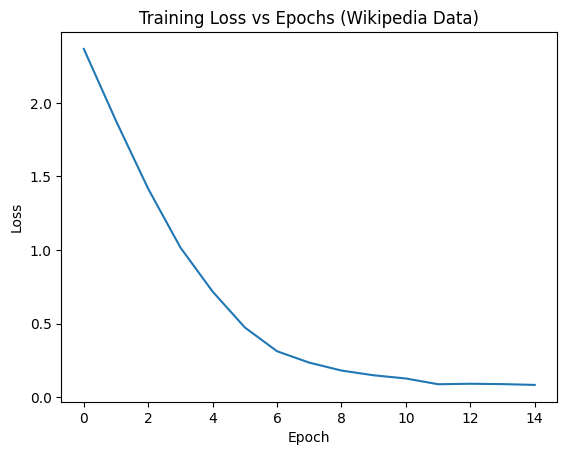

In [135]:
plt.plot(loss_)
plt.title("Training Loss vs Epochs (Wikipedia Data)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()


In [113]:
#Performance on Test data
test_names = test_ppl

test_loss = 0.0
correct = 0
total = 0

model.eval()

with torch.no_grad():

    for person in test_names:

        pdata = memory_data[person]
        keys_main = pdata["keys"]
        vals_main = pdata["vals"]
        R_ = keys_main.shape[0]     # numbr of relations

        # Add 2 random persons
        random_ppl = random.sample(train_ppl, 2)

        # creat memory block
        keys_list = [keys_main]
        vals_list = [vals_main]

        for d in random_ppl:
            pd = memory_data[d]
            keys_list.append(pd["keys"])
            vals_list.append(pd["vals"])

        K_ = torch.cat(keys_list, dim=0).unsqueeze(0).to(device)
        V_ = torch.cat(vals_list, dim=0).unsqueeze(0).to(device)

        for rel_idx, rel in enumerate(pdata["rels"]):

            # q vector
            q_text = f"{person} {rel}"
            Q = multihot_2(q_text, VOCAB).unsqueeze(0).to(device)

            # fwrd pass
            output = model(Q, K_, V_)

            # values
            V_embed = model.B(V_.squeeze(0))

            logits = output @ V_embed.T

            # first part belongs to right person
            local_logits = logits[:, :R_]

            pred = torch.argmax(local_logits, dim=1).item()

            if pred == rel_idx:
                correct += 1

            total += 1

test_acc = 100 * correct / total
print(f"test accuracy: {test_acc:.2f}%")


test accuracy: 78.65%


**Suggestion:** Once you have a model that has decent accuracy, you may want to save it to your Google Drive using ``torch.save()`` and load it when working on the next part of the assignment using ``torch.load()``.

# Part E: Use the Model (5 points)

Given a question in natural language, turn it into a bag of words and feed it into the model with a set of plausible keys and values. Apply the output feature embedding to the full set of values and pick the value with argmax. Return the actual text inside that value (not the bag of words or embedding).

That is, given a natural language question, you are asked to create the $q$ and pick a relevant subset of $k$ and $v$. Run the $q$, $k$, and $v$ through the model and get an answer to the original question.

For example a question might be "When was Alexander Hamilton born?" Depending on how you pre-proessed your data, you may need to extract the entity and the relation.

Write a function that takes in the `question` below, the data, and the model, and outputs the text answer, e.g., "11 january 1755". You must use your ``KVMemNet``.

**Suggestion:** To process a question you will probably want to find the entity and the relation. You may use packages such as [NLTK](https://www.nltk.org/) (already imported), [SpaCY](https://spacy.io/), [Stanza](https://stanfordnlp.github.io/stanza/), or other.

Change the question to test your implementation, but don't delete this cell.

In [ ]:
question = "When was alexander hamilton born?"

**Create your function for using the `KVMemNet` to answer a given question.**

The function should take in the question, data, model, and any other parameters you need. The function should return a text string.

You can create as many cells as necessary. Save the notebook cells showing one example of your input question and output answer. For grading we will look to see that your question is in natural language, the model is used, and the answer is in text. The example doesn't have to be correct. You will analyze your technique later in the report.

In [121]:
def build_memory_from_DB (name, DB, VOCAB, max_rels=20):

    #build keys,values, relation list for a single person (on the fly).

    if name not in DB:
        return None

    info= DB[name]
    keys,vals,rels= [], [], []

    for rel, val in info.items():
        if rel in ["name", "article_title", "signature"]:
            continue
        if val is None or str(val).strip() == "":
            continue

        k_vec = multihot_2(rel, VOCAB)
        v_vec = multihot_2(str(val), VOCAB)

        if torch.sum(v_vec) == 0:
            continue

        keys.append(k_vec)
        vals.append(v_vec)
        rels.append(rel)

    if len(keys) == 0:
        return None

    if len(keys) > max_rels:
        keys = keys[:max_rels]
        vals = vals[:max_rels]
        rels = rels[:max_rels]

    return {
        "keys": torch.stack(keys),
        "vals": torch.stack(vals),
        "rels": rels
    }


def find_name (question, DB): #find the name in the question
    q = question.lower()
    for name in DB.keys():
        if name.lower() in q:
            return name
    return None

def get_answer(question, model, DB, VOCAB):

    device = next(model.parameters()).device

    # find name
    person = find_name(question, DB)
    if person is None:
        return "Person not found" #for names not in DB

    # get keys values
    pdata = build_memory_from_DB(person, DB, VOCAB)
    if pdata is None:
        return "No info found for this person"

    keys = pdata["keys"].to(device).unsqueeze(0)
    vals = pdata["vals"].to(device).unsqueeze(0)
    rels = pdata["rels"]

    Q = multihot_2(question, VOCAB).to(device).unsqueeze(0)

    # frwrd pass
    model.eval()
    with torch.no_grad():

        output = model(Q, keys, vals)
        vals_embed = model.B(vals.squeeze(0))
        logits = output @ vals_embed.T
        pred_idx = torch.argmax(logits, dim=1).item()

    # inference and get the predicted relation
    predicted_relation = rels[pred_idx]        # e.g. "birth_date"
    print('predicted relation: ', predicted_relation)

    answer_text = DB[person][predicted_relation]

    return answer_text



**RESULTS (Q3)**


In [134]:
#Examples - Correct and Incorrect responses
question = "what was alexander hamilton's death place?"
print(question)
print(get_answer(question, model, DB, VOCAB))
print("---")

question = "what was alexander hamilton's bron place?" #notice the incorrect spelling "bron" instead of born yet the right answer is retrieved
print(question)
print(get_answer(question, model, DB, VOCAB))
print("---")

question = "when was alexander hamilton born?"
print(question)
print(get_answer(question, model, DB, VOCAB))
print("---")

question = "where was alexander hamilton born?"
print(question)
print(get_answer(question, model, DB, VOCAB))
print("---")

question = "what was alexander hamilton birth place?"
print(question)
print(get_answer(question, model, DB, VOCAB))
print("---")

question = "alexander hamilton birth place?"
print(question)
print(get_answer(question, model, DB, VOCAB))
print("---")

question = "who was alexander hamiltons spouse?"
print(question)
print(get_answer(question, model, DB, VOCAB))


what was alexander hamilton's death place?
predicted relation:  death_place
new york city new york u
---
what was alexander hamilton's bron place?
predicted relation:  birth_place
charlestown nevis british west indies
---
when was alexander hamilton born?
predicted relation:  religion
presbyterian episcopalian convert
---
where was alexander hamilton born?
predicted relation:  religion
presbyterian episcopalian convert
---
what was alexander hamilton birth place?
predicted relation:  birth_place
charlestown nevis british west indies
---
alexander hamilton birth place?
predicted relation:  birth_place
charlestown nevis british west indies
---
who was alexander hamiltons spouse?
predicted relation:  spouse
elizabeth schuyler


# Part F: Reporting (15 points)

Your report should answer the following three questions:

 **Q1:** What pre-processing of the data did you do? What motivated the design decisions and how did it impact training and any processing of natural language questions (Parts A and D)?

 Hint: This should help one understand any code modifications you made in Parts A and the first part of Part D. But you shouldn't use this to document your code (hopefully you commented your code with code comments and text cells above), but to justify your choices as well as to explain what worked and what didn't work.

 **Q2:** Report on your training on the real data (Part D). Show your loss curve and report on the testing accuracy. There are many ways to implement the training loop, particularly with the choice of keys and values. What decisions did you make when developing your training loop? Justify your decisions. How did they impact the training?

 Hint: This assignment doesn't grade you on how well your model learns---your solution will not be perfect. We focus more on how you worked through the process. This part of the report should show how well your solution worked, but also the intuition for why it works, and to document the things you tried that didn't work.

 **Q3:** Describe your technique on how you process natural language questions (Part E). Provide some examples of your technique answering questions correctly and some examples of your technique answering questions incorrectly. Discuss what causes the failure cases.

 Hint: You are not penalized for incorrectly answered questions---your model will not be perfect---we are looking for honest reflection. Preferably, show the example as code blocks running your model with notebook outputs saved.

 We have provided three prompts below. You can create as many text and code cells as necessary.

**Q1: Report on Data Pre-processing**

The raw Wikipedia Biography dataset is noisy, irregular, and far too large to feed directly into a Key-Value Memory Network. Before training, I needed to reorganize the data into consistent, numeric, memory-ready structures.
This required several important preprocessing steps.


1.   **Cleaning Relations and Removing Noise-** The DB entries include many obscure fields such as article, signature etc. and these fields increase the size of the vocabulary and destabilize training and so i filtered them out. **Effect:** Removing these fields reduces noise, shrinks vocab size, and prevents the KVMemNet from wasting attention on irrelevant information.
2.   **Limiting maximum relations per person-** Some people have 30+ relations, while others fewer than 10. This level of variation makes memory blocks unbalanced and can blow up GPU RAM. So I limited each person to a maximum of 20 relations and if someone had more than 20 relations, I kept the first 20. **Effect:** Training becomes predictable and memory-safe. People with very large relation sets no longer distort the size of memory inputs.
3. **Fixing vocabulary coverage and handling unknown words (`multihot_2()`)-** The original `multihot()` function crashed whenever a token was not in the vocabulary. This happened because the real Wikipedia data contains punctuation and tokens the vocab never saw (unknown words), and so using the original `multihot()` caused repeated crashes due to out-of-vocabulary tokens. To fix this, I created a safer version (`multihot_2()`) that first replaces unknown words with "unk" and then builds the vector. **Effect:** Prevented index errors and ensured every question/key/value can always be vectorized, and kept the vector size consistent across the entire dataset.
4. **Converted Keys, Values, and Questions into GPU-compatible tensors-** The raw multihot vectors were NumPy arrays. I converted them to PyTorch tensors so they could be processed on the GPU by the KVMemNet model.
**Effect:** Ensures compatibility with the models forward pass, especially with matrix multiplications inside the A, C, and B embedding layers.

5. **Simple Question templates for training-** The Wikipedia DB does not provide natural language questions, only key-value facts. To train a KVMemNet, I needed to convert each (person, relation) pair into a question. I used simple templates such as: *"name relation"* (e.g., "alexander hamilton birth date"). I deliberately kept is simple because 1/ simple forms keep the vocabulary small 2/reduce sparsity in multihot vectors 3/improve stability during training 4/ consistent structure helps the model learn relation cues 5/ reduced overhead of leveraging LLMs to create natural questions templates. However in subsequent iterations more natural looking questions should be included. **Effect:** In addition to faster training, these simple questions allowed the model to learn the mapping from a query to correct relation value. They also enabled Part E, where real natural-language questions are mapped into similar bag-of-words vectors.

6. **Constructing per-person memory blocks-** For each person, I built 1/a stack of key vectors (relation names), 2/ a stack of value vectors (relation values), 3/ and a list of relation labels. These together form the “memory matrix” for that person. **Effect:** This mirrors the structure of the synthetic dataset (from Part A), so the same KVMemNet architecture can be trained consistently on the real data.
7. **Train/Test split (500 Train + 100 Test) and Reduced data for training-** The full DB contains ~40,000+ people, which is far too large to process in Colab. Attempting to load all ~40k people caused the session to crash repeatedly, so reducing the dataset size was necessary. The TA guidance confirmed that using a subset is acceptable. Therefore, from the first 600 valid processed people, I used the first 500 for training and the next 100 for testing. **Effect:** 1/ reduces preprocessing and training time, 2/ avoids GPU memory crashes when stacking large key/value tensors, and 3/ provides a clean separation between training and testing people so test results reflect generalization and not memorization.
8. **Impact on natural-language question processing (Part E) –**
The cleaned vocabulary, added "unk" token, and the robust multihot_2 representation ensured that natural-language questions like “Who was X spouse?” always mapped to valid feature vectors. Without these preprocessing steps, Part E would fail immediately due to unknown-token errors or inconsistent vector sizes.




**Q2: Report on Training and Testing**

Training the KVMemNet on real Wikipedia data required several design decisions that differed substantially from the synthetic-data setup in Part A. This section reports my final training approach, shows the resulting loss curve and accuracy, and explains why each design choice was made and how it affected performance.
After preprocessing the real Wikipedia dataset, I trained my KVMemNet on the first 500 people and evaluated on the next 100. Real data introduces significant irregularity (different relation types, different numbers of relations, long text values), so the training loop had to be designed carefully.

1.   **Training Setup and Design Decisions:**
      *   **Using random people in every training step-** In the synthetic dataset from Part A, each example contained only one person in memory, so adding random persons were unnecessary—the memory structure was clean, fixed, and perfectly separable. However, in the real Wikipedia data, if the model only receives the true person's relations, it quickly learns to memorizes the position of each relation within the memory block instead of learning to match questions semantically. To avoid this, for every training example, I added two random persons relations to the memory block. **Effect:** This forces the model to discriminate semantically between competing key-value pairs, significantly improving generalization. Unlike the synthetic setup in Part A, where the model computes logits over a single global Y matrix of all possible values, the real-data implementation instead uses a local memory block (the true person + two random persons). Constructing a global Y for real data would require embedding hundreds of thousands of long text values, which is both memory-infeasible and unnecessary.
      *   **Building a single large memory block per training sample-** Each training pass mixes Keys (*keys_main*) and Values (*vals_main*) from the true person and, Keys and Vals of two randomly sampled people. These are concatenated into a large memory matrix (*K_ and V_*). **Effect:** This ensures the model learns to search through memory rather than memorizing fixed offsets/positions.
      *   **Computing logits only over the true-person's relations-** Even though the model sees all added random persons relations, the target is only one of the true person's relations. So I take logits for all relations but slice only the first relations entries. **Effect:** Prevents the model from incorrectly treating random relations as correct candidates during training.
      *   **Configuration (Epochs, Loss Function, and Optimizer)-** The model was trained for 15 epochs (to avoid long training times due to limited compute). More epochs led to minor improvements, but the curve flattened early. If more time and compute was available I would have run for few more epochs and tried to acheive a higher accuracy. I used Adam with learning rate = 0.001 and CrossEntropyLoss. This gave stable convergence without exploding gradients as seen in the results (output cell above under the code).
  
2.   **Training Results (Loss Curve & Accuracy) -** The model converges quickly and smoothly as shown below (also in the output cell under the training code)

| Epoch | Loss   | Accuracy (%) |
|-------|--------|---------------|
| 0     | 2.3659 | 13.24%        |
| 1     | 1.8773 | 32.43%        |
| 2     | 1.4159 | 50.29%        |
| 3     | 1.0174 | 63.04%        |
| 4     | 0.7183 | 74.64%        |
| 5     | 0.4749 | 84.17%        |
| 6     | 0.3136 | 89.73%        |
| 7     | 0.2363 | 92.33%        |
| 8     | 0.1825 | 94.30%        |
| 9     | 0.1503 | 95.29%        |
| 10    | 0.1287 | 95.65%        |
| 11    | 0.0896 | 96.56%        |
| 12    | 0.0929 | 96.80%        |
| 13    | 0.0905 | 96.78%        |
| 14    | 0.0850 | 96.89%        |

Loss consistently decreases, and accuracy approaches ~97%.

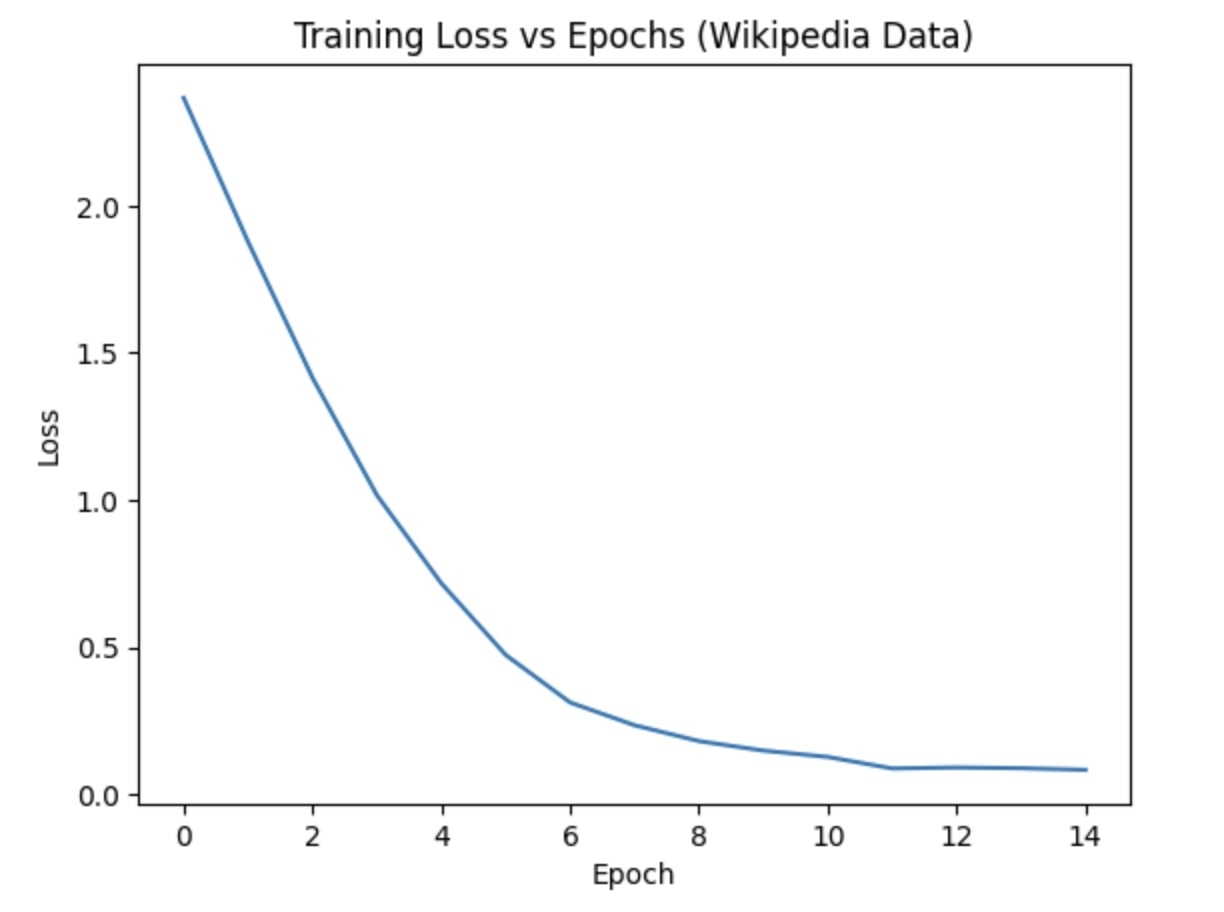

The curve shows smooth exponential decay, indicating that the addition of random persons based memory block is effective and the model is learning stable key–value matching.

3.   **Testing Accuracy (on 100 held-out people)-** After training, I evaluated the model using the same distractor-based logic used in training - 1/build a memory block with the test person + 2 random training people, 2/compute logits and, 3/predict the relation within the test person's block.
The final test accuracy: 78.65% (see the printed output from the test loop in the notebook).
**Effect:** Using the same random person addition structure for testing ensures the models evaluation setup exactly matches the training distribution.
4.   **What worked well and what didn't-**
      *   **Worked Well-** 1/ Adding random persons improved generalization 2/Cleaning relations and limiting memory size made training stable 3/multihot_2() prevented crashes and fixed vocabulary issues 4/Embedding dimension 64 was enough to learn good relational structure
      *   **Didnt work Well-** 1/ Without adding random persons during training the model overfit, 2/Using all relations without limiting to 20 caused GPU memory crashes 3/ limited compute made it hard to execute too many epochs which impacted accuracy.


**Q3: Report on Model Use**

To answer natural-language questions in Part E, I built a lightweight question-processing pipeline that converts an input sentence into a BOW vector compatible with the KVMemNet's input representation. Since the model was trained only on BoW vectors, rather than full text or sequences, the question-processing step had to align precisely with the format used during training.


1.   **Technique for processing natural language questions:**
      *   **Step 1 — Detect the person (name) in the question:** I scanned the question and matched it against the list of names available in DB (full Wikipedia dataset). This was done using simple string matching after lower-casing and removing punctuation. This allows the model to answer questions about any of the 40,000+ people, even those unseen during training. However, if the person is not in DB, the model cannot answer the question, because it has no key/value memories for that person.
      *   **Step 2 — Rebuild a persons memory on the fly from the original DB:** - When answering questions about a person, instead of using the precomputed training memory (which is only for 600 selected people), I extract the relations directly from DB. This is what is used to answer quetsions about any person in DB. It includes, 1/creating clean unwanted relations (same preprocessing as Part D), 2/create multihot key vectors (relation names), 3/create multihot value vectors (relation values), 4/ limit to 20 relations if there are more. This ensures the memory format at inference matches the training format.
      *   **Step 3 — Convert the question into a multihot vector using `multihot_2()`:** - This is importatnt because 1/ unknown tokens are safely mapped to `unk` 2/ vector size always matches VOCAB.num_words() and 3/representation matches what the model was trained on
      *   **Step 4 — Feed question, keys, and values into the trained KVMemNet:** - The question vector and the persons keys/values are passed to the trained KVMemNet. The model produces an `output` embedding representing its guess about the answer. Each value is also embedded using the models B matrix, and the model compares its output to every value embedding using dot-product similarity. Whichever value scores highest (argmax) determines the predicted relation, and using that relation label, I retrieve the actual text answer from the DB.
      *   **Step 5 — Map the predicted index back to a relation and retrieve the text answer:** The predicted index identifies which relation in the persons memory block the model believes is correct. I use this index to look up the relation name (e.g., "`birth_date`") and then fetch the corresponding text answer directly from the DB (e.g., `"11 january 1755"`).

2.   **Examples of Correct Answers** Below are examples of correct responses produced by the model (also available above in the code; Refer to the output cell in Part E):

*Note: alexander hamilton was not in training dataset.*

Question 1: "what was alexander hamilton's death place?"
--
Predicted relation: death_place

Answer: new york city new york u
___

Question 2: "what was alexander hamilton's bron place?" (incorrect spelling)
--
Predicted relation: birth_place

Answer: charlestown nevis british west indies
___

Question: "what was alexander hamilton birth place?"
---
Predicted relation: birth_place

Answer: charlestown nevis british west indies
___

Question: "who was alexander hamiltons spouse?"
--
Predicted relation: spouse

Answer: elizabeth schuyler
___

These show that the model successfully handles:

*   spelling mistakes (“bron” → birth_place)
*   paraphrased templates
*   missing capitalization
*   minimal context queries (“alexander hamilton birth place?”)

2.   **Examples of Incorrect Answers and Failure Analysis** Below are examples of incorrect responses produced by the model (also available above in the code; Refer to the output cell in Part E). Some questions produced wrong relation predictions:

Question: "when was alexander hamilton born?"
--
Predicted relation: religion

Answer: presbyterian episcopalian convert
___

Question:
--
Predicted relation: religion

Answer: presbyterian episcopalian convert
___

3.   **Why Do These Failure Cases Occur?**

Most incorrect answers come from a mismatch between the language patterns the model saw during training and the phrasing of real natural language questions. Even though the model sometimes answers natural language questions correctly, it also fails on questions that look very similar. These successes and failures can be traced to how the model was trained and how the question text is converted into BOW vectors.

* **Training only used a single template (“name relation”) — not real questions** The model was trained only on a single simple template (“name relation”). During training, every question looked like: `alexander hamilton birth_place`. So the model learns to associate relation words only in this exact format. When the user asks: `“Where was Alexander Hamilton born?”`
the token “born” appears, but the model never saw this phrasing during training, so the question vector does not strongly activate the `birth_place` relation. Secondly, the model never saw natural human phrasing, such as: `“Where was Alexander Hamilton born?”`, `“When did Alexander Hamilton die?”`, `“Who was Hamilton's spouse?”` etc. So generalization depends entirely on accidental word overlap with relation words, not true language understanding.
* **Why some natural-language questions still worked-** Some of the test questions happened to include words that appear inside the relation names.
For example: `“alexander hamilton birth place?”` Contains the tokens “birth” and “place”, which map almost directly to the key birth_place so we get correct answer. Similarly when answering `“what was alexander hamilton's bron place?”` Even with a typo (“bron”), the words “place” and sometimes “birth” still overlap with the relation name and give correct answer. These work because the question's BOW vector shares vocabulary with the exact relation key.
* **Why other natural-language questions fail-** Questions like: `“Where was Alexander Hamilton born?”` and `“When was Alexander Hamilton born?”` do not contain the literal tokens “birth_place” or “birth_date”.
Instead they contain words like: `where`, `when` and `born`. None of these words ever appeared during training in relation keys, so the model does not associate them with the correct relation. As a result, the question vector may accidentally match a different key, such as religion or party, leading to incorrect predictions.

* **Vocabulary mismatch between questions and relation names-** Relation keys in the memory look like: `birth_place` `birth_date` `spouse`. But natural questions use completely different vocabulary (“where”, “when”, “who”). Since the model is purely BOW based and has no semantic understanding, it cannot infer that:

“born” ≈ “birth”

“where” ≈ “place”

“when” ≈ “date”

So failures happen whenever vocabulary does not closely overlap.

